# Transformer-to-VLA

## Vision Transformers

### 面向多模态模型的 Visual Token Projection

---

**目标**

理解如何投影视觉特征，使其维度与多模态 Transformer 的 Token 接口兼容。

**核心概念**

- Vision Encoder Output
- Visual Tokens
- Feature Projection
- Token Dimension Alignment
- Multimodal Attention

**实现**

本 Notebook 演示视觉表征的投影，以及投影结果与其他模态 Token 的组合方式。

**学习重点**

理解视觉信息如何转换为 Transformer 可处理的 Token，为多模态学习建立接口层面的认识。

In [1]:
import math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.manual_seed(42); np.random.seed(42); random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


## 1. 构造 RGB 图像与文本 Token

使用两个简单 RGB 图像样例，以及示意性指令：`move to target` 和 `avoid obstacle`。

这里的整数 Token ID 是人为指定的**示例编码**，不是预训练模型的 tokenizer。

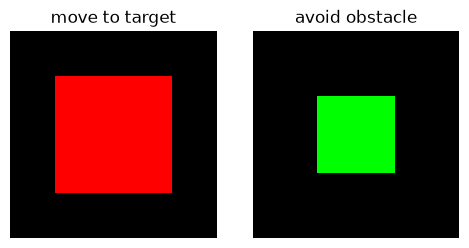

images: torch.Size([2, 3, 32, 32]) text IDs: torch.Size([2, 3])


In [2]:
B, IMAGE_SIZE, PATCH_SIZE = 2, 32, 8
images = torch.zeros(B, 3, IMAGE_SIZE, IMAGE_SIZE)
images[0, 0, 7:25, 7:25] = 1.0  # red square
images[1, 1, 10:22, 10:22] = 1.0 # green square
vocab = {'<pad>':0, 'move':1, 'to':2, 'target':3, 'avoid':4, 'obstacle':5}
text_ids = torch.tensor([[1, 2, 3], [4, 5, 0]], dtype=torch.long)
fig, ax = plt.subplots(1, 2, figsize=(5, 2.5))
for i in range(B):
    ax[i].imshow(images[i].permute(1, 2, 0)); ax[i].set_title(['move to target', 'avoid obstacle'][i]); ax[i].axis('off')
plt.tight_layout(); plt.show()
print('images:', images.shape, 'text IDs:', text_ids.shape)

## 2. 视觉编码：Patch Tokens

真实 VLA 的 Vision Encoder 常采用预训练 ViT/SigLIP 等。为了保持独立运行，这里使用 **ViT-style patch projection + one Transformer encoder**。

$$
Z_v = f_{\mathrm{vision}}(I)\in\mathbb R^{B\times N_v\times D_v}
$$

其中 `N_v = (32/8)² = 16`，`D_v = 64`。

这里复用 `nn.TransformerEncoder` 的默认 Post-LN / ReLU 配置，作为独立的编码器示意；前一节的 TinyViT 使用 Pre-LN / GELU。本节没有加载前一节训练好的权重。改变 `IMAGE_SIZE` 或 `PATCH_SIZE` 后，请从头执行，位置嵌入长度会按网格大小重新创建。


In [3]:
class ToyVisionEncoder(nn.Module):
    def __init__(self, image_size=32, patch_size=8, dv=64):
        super().__init__()
        assert patch_size > 0 and image_size % patch_size == 0
        self.image_size = image_size
        self.grid_size = image_size // patch_size
        self.num_patches = self.grid_size ** 2
        self.patch = nn.Conv2d(3, dv, kernel_size=patch_size, stride=patch_size)
        self.pos = nn.Parameter(torch.randn(1, self.num_patches, dv) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=dv, nhead=4, dim_feedforward=128,
                                           dropout=0.0, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1, enable_nested_tensor=False)
    def forward(self, x):
        if x.shape[-2:] != (self.image_size, self.image_size):
            raise ValueError("Input image size must match the configured image_size")
        patches = self.patch(x).flatten(2).transpose(1, 2)
        return self.encoder(patches + self.pos)

D_V = 64
vision_encoder = ToyVisionEncoder(image_size=IMAGE_SIZE, patch_size=PATCH_SIZE, dv=D_V).to(device)
visual_features = vision_encoder(images.to(device))
print('visual features:', visual_features.shape)
N_V = vision_encoder.num_patches
assert visual_features.shape == (B, N_V, D_V)

visual features: torch.Size([2, 16, 64])


## 3. Visual Projector：隐藏维度对齐

视觉编码器与语言模型的隐藏维度通常不同。最简单的方案是线性投影：

$$
Z_v^{\mathrm{LLM}} = Z_v W_p^\top+b_p
$$

下面模拟 `D_v=64 → D_LLM=96`。与 PyTorch `nn.Linear` 一致，权重 $W_p\in\mathbb R^{D_{\mathrm{LLM}}\times D_v}$，输入沿最后一维右乘其转置，偏置 $b_p$ 广播到每个视觉 Token。

> 维度对齐只是接口的**必要条件之一**。未经训练的 Projector 并不会自动产生视觉—语言语义对齐。

In [4]:
D_LLM = 96
visual_projector = nn.Linear(D_V, D_LLM).to(device)
text_embedding = nn.Embedding(len(vocab), D_LLM, padding_idx=vocab['<pad>']).to(device)
visual_tokens = visual_projector(visual_features)
text_tokens = text_embedding(text_ids.to(device))
print('visual:', visual_tokens.shape, '| text:', text_tokens.shape)
assert visual_tokens.shape[-1] == text_tokens.shape[-1]

visual: torch.Size([2, 16, 96]) | text: torch.Size([2, 3, 96])


## 4. 融合 Token 序列并执行 Attention

将图像 Token 作为前缀，后接文本 Token：

$$
Z = [Z_v^{\mathrm{LLM}};Z_l]\in\mathbb R^{B\times (N_v+N_l)\times D_{\mathrm{LLM}}}
$$

接着用 Multi-Head Self-Attention 让两类 Token 交互。为了清楚展示连接关系，这里使用**非因果的双向 Self-Attention**；真实自回归 VLM 通常需要满足特定的因果或前缀注意力掩码。

`key_padding_mask=True` 只屏蔽该位置作为 Key/Value 的贡献，不会将对应 Query 的输出行自动置零。实际逐 Token 损失需要另外忽略 padding 位置。这里还省略了文本位置编码，所以只能演示信息交互，不能学习词序语义。


In [5]:
combined = torch.cat([visual_tokens, text_tokens], dim=1)
attn = nn.MultiheadAttention(D_LLM, num_heads=4, batch_first=True, dropout=0.0).to(device)
# mask padded text KEY (last position of sample 2)
key_padding_mask = torch.cat([
    torch.zeros(B, visual_tokens.shape[1], dtype=torch.bool),
    text_ids.eq(vocab['<pad>'])
], dim=1).to(device)
attended, weights = attn(combined, combined, combined,
                         key_padding_mask=key_padding_mask,
                         need_weights=True, average_attn_weights=False)
print('combined:', combined.shape, 'attended:', attended.shape, 'attention:', weights.shape)
sequence_length = N_V + text_ids.shape[1]
assert combined.shape == (B, sequence_length, D_LLM)
assert weights.shape == (B, attn.num_heads, sequence_length, sequence_length)
assert torch.all(weights.masked_select(key_padding_mask[:, None, None, :]) == 0)

combined: torch.Size([2, 19, 96]) attended: torch.Size([2, 19, 96]) attention: torch.Size([2, 4, 19, 19])


## 5. 逐 Head 查看 Text Token 对 Image Tokens 的 Attention

取第一个样本、最后一个非 Padding 文本 Token 的 Query，分别查看 4 个 Head 对 `N_V` 个视觉 Token 的注意力权重（默认 16 个），不在 Head 维度求平均。这里的文本在右侧 Padding，因此用有效文本长度计算 Query 的位置。

各热力图保留原始权重，共用从 0 到本样本全部 Attention 权重最大值的色标，便于跨 Head 比较绝对值。`visual_mass` 分别统计每个 Head 分配给视觉 Key 的权重总和；由于还有文本 Key，该总和不必等于 1。

**注意：本网络未训练，权重没有任务语义，仅用来展示维度及信息流。**


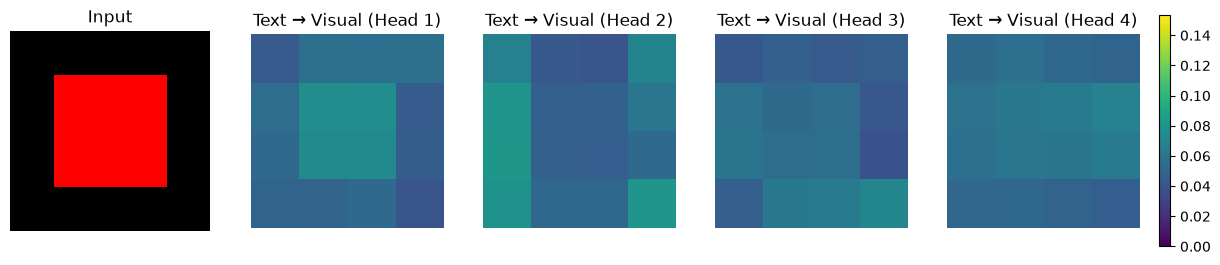

Visual-key attention mass per head: [0.8958491683006287, 0.9421989917755127, 0.8366949558258057, 0.89402174949646]


In [6]:
w = weights.detach().cpu()[0]  # (4, 19, 19)
text_length = int(text_ids[0].ne(vocab['<pad>']).sum())  # right-padded text
last_text_idx = N_V + text_length - 1
grid_size = vision_encoder.grid_size
visual_attention = w[:, last_text_idx, :N_V].reshape(4, grid_size, grid_size).numpy()

fig, axs = plt.subplots(1, 5, figsize=(15, 3))
axs[0].imshow(images[0].permute(1, 2, 0)); axs[0].set_title('Input')
for h in range(4):
    im = axs[h+1].imshow(visual_attention[h], cmap='viridis', vmin=0, vmax=w.max().item())
    axs[h+1].set_title(f'Text → Visual (Head {h+1})')
for a in axs: a.axis('off')
fig.colorbar(im, ax=axs[1:], fraction=0.015, pad=0.02)
plt.show()

visual_mass = w[:, last_text_idx, :N_V].sum(-1)
print('Visual-key attention mass per head:', visual_mass.tolist())


## 6. 检查跨模态计算图是否连通

构建一个仅用于演示的标量 Loss（**不是语义训练目标**）。检查输出文本 Token 的梯度是否能回传到视觉 Projector。

In [7]:
visual_projector.zero_grad(set_to_none=True)
attn.zero_grad(set_to_none=True)
# one scalar from last text token; use non-symmetric weighted projection to avoid degeneracy
probe = torch.linspace(-1, 1, D_LLM, device=device)
loss = (attended[0, last_text_idx] * probe).sum()
loss.backward()
grad_norm = visual_projector.weight.grad.norm().item()
print(f'Projector grad norm from text-token output: {grad_norm:.6f}')
assert grad_norm > 0

Projector grad norm from text-token output: 9.463445


## 7. 与 π₀ / VLA 的联系和边界

当前演示说明：

1. ViT-style Encoder 产生 **多个** Visual Tokens。
2. Projector 把视觉和语言特征映射到兼容的隐藏维度。
3. Attention 可以在视觉 Token 与文本 Token 间传递信息。

但是这个 Notebook **没有训练视觉语言对齐、没有使用真实 tokenizer、没有实现 PaliGemma / SigLIP 的权重结构，也没有实现 π₀ 的 Action Expert**。真实 π₀ 的 Action Expert 并非简单附加一个线性分类头；这些内容留到后续 VLA 章节。

### 练习

- 把 `D_LLM` 调整为 128，观察所有张量的形状变化。
- 将 `PATCH_SIZE` 从 8 改为 4，从头执行：视觉 Token 从 16 个变为 64 个，位置嵌入、拼接序列长度和热力图网格如何变化？
- 为什么仅有随机初始化的 Projector 不能实现图像—文字语义对齐？
- 对比本实验的双向 Attention 与自回归 VLM 的因果 Attention。

**下一阶段**：在第五章学习多模态融合；在 VLA 章节学习真实的预训练 Vision Encoder、VLM 和 Action Expert。

参考：[PyTorch Linear](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html)、[MultiheadAttention](https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html)。

[上一实验：ViT from Scratch](https://github.com/Maple-Ze/Transformer-to-VLA/blob/main/03_Vision_Transformers/01_ViT_From_Scratch.ipynb) · [返回项目首页](https://github.com/Maple-Ze/Transformer-to-VLA/blob/main/README.md)
